# Collaboration step 2: the specified score, the data audit and the sensitivity analysis

Protocol: [PROTOCOL.md](../PROTOCOL.md). The score is the equal-weight mean of six measures with an evidence gate (`score.py`); nothing here is fitted. This notebook
(1) scores every real and simulated student-sprint, (2) reports how many can be scored at all (the audit), (3) measures how much the ranking depends on the two design
assumptions, equal weights and the count caps, and (4) checks the invariants. The simulated students and their texts were written by the assistant: they exercise the
pipeline, they do not measure accuracy.

In [1]:
import sys, warnings, json, importlib.util
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(".").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
import student_evidence as se
spec = importlib.util.spec_from_file_location("collab_score_nb", Path("..") / "score.py")
S = importlib.util.module_from_spec(spec); spec.loader.exec_module(S)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

## 1. Score every student-sprint

In [2]:
rows = []
for meta, ev in se.real() + se.simulated():
    r = S.assess(ev)
    rows.append({**meta, "score": r["score"], "available": r["score"] is not None, "interval_lo": (r["interval"] or [None, None])[0], "interval_hi": (r["interval"] or [None, None])[1],
                 "team_activity": ev["team"]["reviews_and_comments"], **{k: v for k, v in r["features"].items()}})
res = pd.DataFrame(rows)
print(len(res), "student-sprints:", res.groupby("source").size().to_dict())

319 student-sprints: {'real': 144, 'simulated': 175}


## 2. Data audit: how many student-sprints can be scored

In [3]:
def summary(d):
    n = len(d); a = int(d.available.sum())
    return pd.Series({"student-sprints": n, "team reviewed (score available)": a, "not available (team never reviewed)": n - a,
                      "available and score = 0": int((d.score == 0).sum()), "available and score > 0": int((d.score > 0).sum()),
                      "student wrote any review or comment text": int(((d.Co_count_review_texts + d.Co_count_discussion_texts) > 0).sum())})
gate = res.groupby("source").apply(summary).T
gate

source,real,simulated
student-sprints,144,175
team reviewed (score available),8,128
not available (team never reviewed),136,47
available and score = 0,1,17
available and score > 0,7,111
student wrote any review or comment text,5,37


## 3. Score distribution

Real student-sprints with a score:


,student,team,sprint,score,interval_lo,interval_hi,Co_count_substantive_texts,Co_count_trivial_texts,Co_count_reviewed_prs
72,STU-002,T08,T08-S1,0.20,0.012,0.605,0,4,0
73,STU-008,T08,T08-S1,0.20,0.012,0.605,0,1,0
74,STU-016,T08,T08-S1,0.00,0.000,0.000,0,0,0
75,STU-025,T08,T08-S1,0.25,0.021,0.668,0,0,0
76,STU-002,T08,T08-S2,0.20,0.012,0.605,0,2,0
77,STU-008,T08,T08-S2,0.25,0.021,0.668,0,0,0
78,STU-016,T08,T08-S2,0.20,0.012,0.605,0,1,0
79,STU-025,T08,T08-S2,0.20,0.012,0.605,0,4,0


Simulated student-sprints with a score: n = 128


,count,mean,std,min,25%,50%,75%,max
score,128.0,0.311,0.221,0.0,0.25,0.25,0.25,0.812


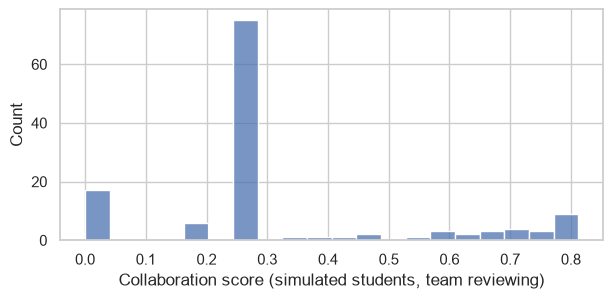

In [4]:
print("Real student-sprints with a score:")
display(res[(res.source == "real") & res.available][["student", "team", "sprint", "score", "interval_lo", "interval_hi", "Co_count_substantive_texts", "Co_count_trivial_texts", "Co_count_reviewed_prs"]].round(3))
sim = res[(res.source == "simulated") & res.available]
print("Simulated student-sprints with a score: n =", len(sim)); display(sim.score.describe().round(3).to_frame().T)
fig, ax = plt.subplots(figsize=(7, 3)); sns.histplot(sim.score, bins=20, ax=ax); ax.set_xlabel("Collaboration score (simulated students, team reviewing)"); plt.show()

## 4. Sensitivity to the design assumptions

Spearman correlation of each variant's ranking with the default ranking. Target (fixed in PROTOCOL.md before the run): median >= 0.90 and minimum >= 0.80.

In [5]:
caps_scales = (0.5, 1.0, 2.0)
N_WEIGHTS = 1000
rng = np.random.default_rng(7)
W = rng.dirichlet(np.ones(len(S.MEASURES)), size=N_WEIGHTS)            # equal on average

def score_matrix(ev_list, scale, weights_list):
    """scores[i, j]: student-sprint i under weighting j and the caps scaled by `scale`."""
    ms = [S.measures(ev, {k: v * scale for k, v in S.CAPS.items()})[0] for ev in ev_list]
    return np.array([[S.combine(m, dict(zip(S.MEASURES, w))) for w in weights_list] for m in ms], dtype=float), ms

def rank_corr(a, b):
    ok = ~(np.isnan(a) | np.isnan(b))
    if ok.sum() < 3 or np.ptp(a[ok]) == 0 or np.ptp(b[ok]) == 0:
        return np.nan
    return spearmanr(a[ok], b[ok]).correlation

equal = [np.full(len(S.MEASURES), 1 / len(S.MEASURES))]
out, per_source = [], {}
for source, items in (("real", se.real()), ("simulated", se.simulated())):
    items = [(m, e) for m, e in items if S.assess(e)["score"] is not None]
    evs = [e for _, e in items]
    base, _ = score_matrix(evs, 1.0, equal)
    base = base[:, 0]
    for scale in caps_scales:
        mat, _ = score_matrix(evs, scale, list(W) if scale == 1.0 else equal)
        if scale == 1.0:
            rs = [rank_corr(base, mat[:, j]) for j in range(N_WEIGHTS)]
            out.append({"source": source, "variant": f"{N_WEIGHTS} random weightings (caps 1x)", "n": len(evs), "median": np.nanmedian(rs), "p5": np.nanpercentile(rs, 5), "min": np.nanmin(rs)})
        else:
            # caps scaled, combined with the same random weightings as well, to cover both assumptions together
            mat2, _ = score_matrix(evs, scale, list(W[:200]))
            rs = [rank_corr(base, mat2[:, j]) for j in range(mat2.shape[1])]
            out.append({"source": source, "variant": f"caps x{scale} with equal weights", "n": len(evs), "median": rank_corr(base, mat[:, 0]), "p5": np.nan, "min": rank_corr(base, mat[:, 0])})
            out.append({"source": source, "variant": f"caps x{scale} with 200 random weightings", "n": len(evs), "median": np.nanmedian(rs), "p5": np.nanpercentile(rs, 5), "min": np.nanmin(rs)})
sens = pd.DataFrame(out).round(3)
sens["meets target (median >= 0.90, min >= 0.80)"] = (sens["median"] >= 0.90) & (sens["min"] >= 0.80)
sens.to_csv(RESULTS / "fixed_score_sensitivity.csv", index=False)
sens

,source,variant,n,median,p5,min,"meets target (median >= 0.90, min >= 0.80)"
0,real,caps x0.5 with equal weights,8,1.000,NaN,1.000,True
1,real,caps x0.5 with 200 random weightings,8,1.000,1.000,1.000,True
2,real,1000 random weightings (caps 1x),8,1.000,1.000,1.000,True
3,real,caps x2.0 with equal weights,8,1.000,NaN,1.000,True
4,real,caps x2.0 with 200 random weightings,8,1.000,1.000,1.000,True
5,simulated,caps x0.5 with equal weights,128,0.996,NaN,0.996,True
6,simulated,caps x0.5 with 200 random weightings,128,0.995,0.867,0.141,False
7,simulated,1000 random weightings (caps 1x),128,0.999,0.785,0.078,False
8,simulated,caps x2.0 with equal weights,128,0.999,NaN,0.999,True
9,simulated,caps x2.0 with 200 random weightings,128,0.998,0.426,0.101,False


## 5. Face check on the simulated behaviour classes

The classes were written to differ in reviewing; a score that does not separate them would be wrong. This checks the direction only (assistant-written data).

In [6]:
sim = res[(res.source == "simulated")]
face = sim.groupby("behaviour").agg(student_sprints=("score", "size"), available=("available", "sum"), mean_score=("score", "mean"),
                                    mean_review_texts=("Co_count_review_texts", "mean"), mean_trivial=("Co_count_trivial_texts", "mean")).round(3).sort_values("mean_score", ascending=False)
face

,student_sprints,available,mean_score,mean_review_texts,mean_trivial
behaviour,,,,,
reviewer_coordinator,25,23,0.689,3.520,0.800
burst_worker,27,17,0.283,0.111,0.037
consistent_deep_contributor,28,20,0.263,0.143,0.071
no_specific_pattern,37,28,0.262,0.162,0.027
last_minute_rusher,30,20,0.240,0.133,0.133
free_rider,28,20,0.088,0.000,0.000


## 6. Invariants

Run of the unit tests (gate, approvals/padding/self/bot do not raise the score, monotonic in substantive reviews, determinism, weights renormalise).

In [7]:
import subprocess
r = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "04_collaboration/tests"], cwd=str(Path("..").resolve().parent), capture_output=True, text=True)
print((r.stdout + r.stderr).strip().splitlines()[-4:])

['----------------------------------------------------------------------', 'Ran 22 tests in 3.882s', '', 'OK']


## 7. Reading the results

**Audit (real students).** Of 144 real student-sprints only 8 (all in team T08, sprints 1 and 2) can be scored, because in every other team-sprint nobody reviewed or commented on anyone else's pull request. The other 136 return "not available" and fusion redistributes the weight instead of treating them as low. The 8 scored sprints contain only approval-style texts ("All good", "ok", "well done"): no substantive text at all. Their scores (0.20 to 0.25, 0.00 for one student with nothing) come entirely from the response-rate measure (own pull requests resolved). The real data therefore says almost nothing about Collaboration, and nothing about how well the score separates good from poor collaborators.

**Simulated students (assistant-written, pipeline check only).** 128 of 175 student-sprints are scored (47 are in teams without any review in that sprint). The behaviour classes order as intended: the reviewer/coordinator class averages 0.69, the free riders 0.09, the other classes 0.24 to 0.28. The score also rejects approvals, padding, self-comments and bots (unit tests, all 22 pass).

**Known weakness found by the audit (not changed after seeing it).** 75 of the 128 scored simulated sprints sit at exactly 0.25: a student who only merged their own pull requests gets full marks on the response-rate measure and nothing else, so that one measure yields a quarter of the score and a large tie. Merging your own work is not collaboration; the measure as specified (share of own pull requests resolved) cannot tell, because the evidence has no information on whether anyone else engaged with those pull requests. A better definition needs per-pull-request counts of other people's reviews and comments, which the agent can supply but the collected data does not carry. Changing it now would be a post-hoc change to the protocol; it is listed as a recommended amendment instead.

**Sensitivity.** The ranking is stable to the count caps (Spearman 0.996 to 0.999 against the default for caps halved or doubled, equal weights). Under random weightings the median stays at 0.995 to 0.999, which meets the fixed target, but the lower tail does not: on the simulated students the 5th percentile is 0.79 (caps unchanged), 0.87 (caps halved) and 0.43 (caps doubled), each with random weights and the minimum is 0.08 to 0.14, below the target of 0.80. The cause is the tie at 0.25 above: when the weight shifts toward response rate or away from it the tied group re-orders. The sensitivity target is therefore **not fully met** for the simulated students. On the real students all variants correlate 1.0, which only reflects that there are 8 nearly identical scores.

**Reported interval.** The interval returned with each score is the 5th to 95th percentile under random weightings and caps; for the real T08 scores it is wide (about 0.01 to 0.6), which is the honest statement of how little the design fixes the value for students whose only evidence is approvals.

In [8]:
res.to_csv(RESULTS / "fixed_score_all.csv", index=False)
summary_json = {"gate": gate.to_dict(), "sensitivity_target_met": bool(sens["meets target (median >= 0.90, min >= 0.80)"].all()), "score_version": S.SCORE_VERSION}
(RESULTS / "fixed_score_summary.json").write_text(json.dumps(summary_json, indent=1, default=str), encoding="utf-8")

597